In [ ]:
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
from scipy.stats import linregress
import pandas as pd
from matplotlib.colors import CenteredNorm, Normalize
from tqdm import tqdm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid, SparseGrid
from mg_sampling.density.utils import indices_to_mask, voxels_around
from mg_sampling.tools import edges_to_range, bayesian_bootstrap

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [44]:
ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")
masks = {
    'RNA-Shell': indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params),
    'RNA': indices_to_mask(voxels_around(rna, 1.8, ref_map.grid_params), ref_map.grid_params),
    'Phosphates': indices_to_mask(voxels_around(rna.select_atoms('name P'), 6, ref_map.grid_params), ref_map.grid_params)
}

masks['Shell'] = masks['RNA-Shell'] & ~masks['RNA']
masks['Phosphates-Shell'] = masks['Phosphates'] & ~masks['RNA']

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    map_ = SparseGrid.load(filename)
    map_ = map_.to_dense().apply_tempfactor(30)

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=map_,
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [45]:
labeldict = {
    'plain_md_7ez0_mMg_tip3p': "μMg (MD)",
    'plain_md_7ez0_nMg_tip3p': "nMg (MD)",
    'plain_md_7ez0_nMg_tip3p_soft': "nMg (MD-soft)",
    'plain_md_7ez0_noion_nMg_tip3p': "nMg (MD-denovo)",
    'plain_md_7ez0_nomg_mMg_tip3p': "$\emptyset$Mg (MD)",
    'replex_7ez0_mMg_tip3p': "μMg (REx)",
    'replex_7ez0_noion_mMg_tip3p': "μMg (REx-denovo)",
}

In [55]:
results = []

for k, mask in masks.items():
    for sim, group in tqdm(gen_maps.groupby("sim")[["map", "weight"]]):
        ref_data = ref_map.grid[mask]
        def statistic(maps, weights=None):
            return linregress(
                np.average(maps, weights=weights),
                ref_data,
            ).rvalue
        mapsA = group["map"].apply(lambda x: x.grid[mask]).to_numpy()
        weightsA = group["weight"].to_numpy()
        mapA = np.average(mapsA, weights=weightsA, axis=0)
        cc = linregress(
            mapA,
            ref_data,
        ).rvalue

        cc_low, cc_high = bayesian_bootstrap(
            mapsA,
            statistic,
            weights=weightsA,
            n_resamples=100,
        ).confidence_interval

        results.append(
            {
                "sim": sim,
                "mask": k,
                "cc": cc,
                "cc_low": cc_low,
                "cc_high": cc_high,
            }
        )

100%|██████████| 7/7 [00:04<00:00,  1.63it/s]


In [65]:
pd.DataFrame(results).sort_values("cc").style.background_gradient(axis=None).format(precision=3)

,sim,mask,cc,cc_low,cc_high
30,plain_md_7ez0_nMg_tip3p_soft,Phosphates-Shell,0.153,0.134,0.163
23,plain_md_7ez0_nMg_tip3p_soft,Shell,0.250,0.235,0.257
32,plain_md_7ez0_nomg_mMg_tip3p,Phosphates-Shell,0.259,0.252,0.263
31,plain_md_7ez0_noion_nMg_tip3p,Phosphates-Shell,0.283,0.276,0.285
34,replex_7ez0_noion_mMg_tip3p,Phosphates-Shell,0.283,0.277,0.284
28,plain_md_7ez0_mMg_tip3p,Phosphates-Shell,0.295,0.289,0.297
29,plain_md_7ez0_nMg_tip3p,Phosphates-Shell,0.301,0.296,0.302
33,replex_7ez0_mMg_tip3p,Phosphates-Shell,0.302,0.297,0.303
25,plain_md_7ez0_nomg_mMg_tip3p,Shell,0.325,0.317,0.328
27,replex_7ez0_noion_mMg_tip3p,Shell,0.344,0.339,0.345


In [58]:
results

[{'sim': 'plain_md_7ez0_mMg_tip3p',
  'mask': 'RNA-Shell',
  'cc': np.float64(0.7133205693194028),
  'cc_low': np.float64(0.7098125500068326),
  'cc_high': np.float64(0.7138356373186518)},
 {'sim': 'plain_md_7ez0_nMg_tip3p',
  'mask': 'RNA-Shell',
  'cc': np.float64(0.7160517157732333),
  'cc_low': np.float64(0.7125873219071264),
  'cc_high': np.float64(0.7165011422979084)},
 {'sim': 'plain_md_7ez0_nMg_tip3p_soft',
  'mask': 'RNA-Shell',
  'cc': np.float64(0.570708190461957),
  'cc_low': np.float64(0.5259180982652333),
  'cc_high': np.float64(0.5834489268675844)},
 {'sim': 'plain_md_7ez0_noion_nMg_tip3p',
  'mask': 'RNA-Shell',
  'cc': np.float64(0.7083391747552673),
  'cc_low': np.float64(0.7049373124167813),
  'cc_high': np.float64(0.7092499089652331)},
 {'sim': 'plain_md_7ez0_nomg_mMg_tip3p',
  'mask': 'RNA-Shell',
  'cc': np.float64(0.7037814036817226),
  'cc_low': np.float64(0.6982707093556562),
  'cc_high': np.float64(0.7075022795908896)},
 {'sim': 'replex_7ez0_mMg_tip3p',
  'mas

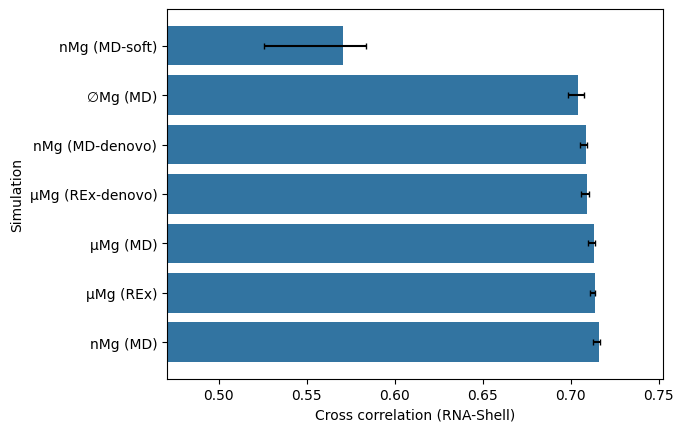

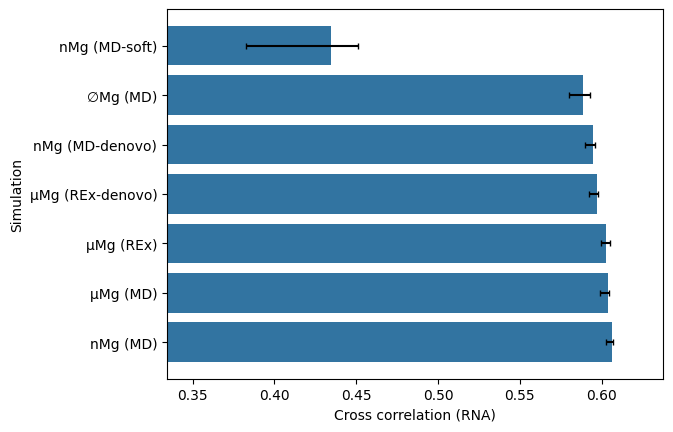

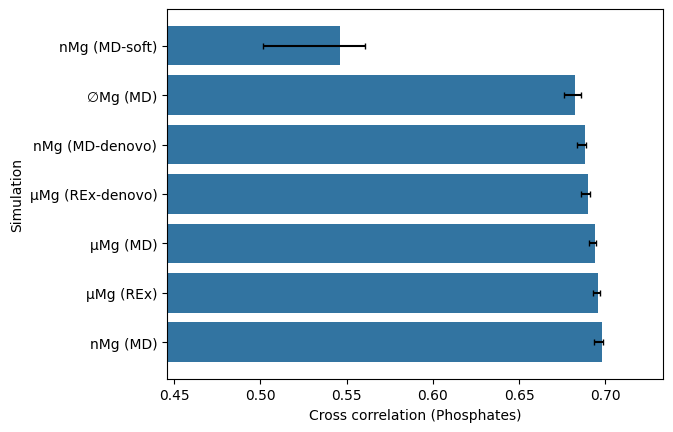

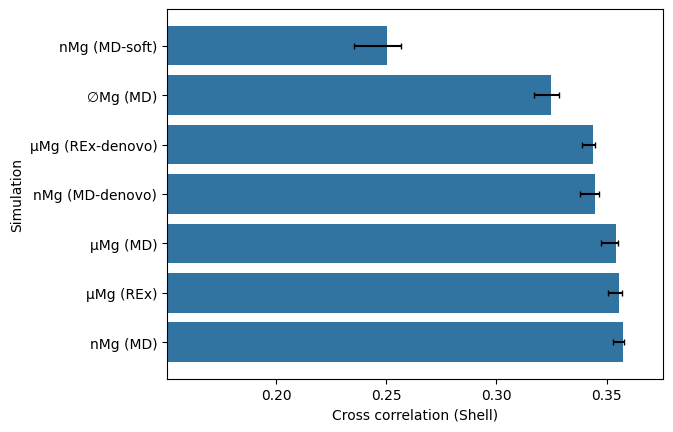

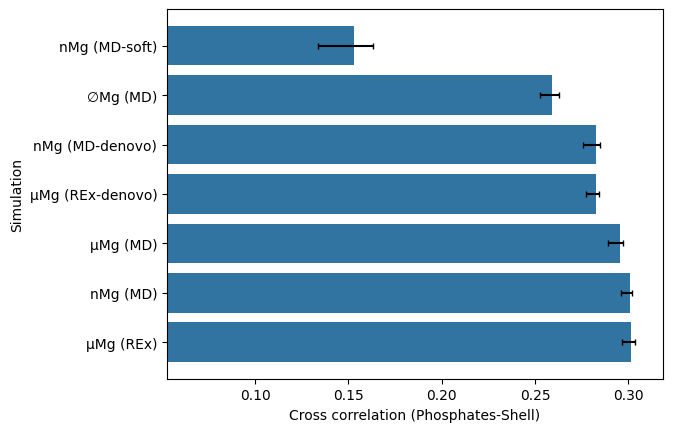

In [63]:
import seaborn as sns

for k in masks:
    df = pd.DataFrame(results).query("mask == @k")
    df['sim_label'] = df['sim'].map(labeldict)
    df = df.sort_values("cc")

    ax = sns.barplot(
        df,
        y='sim_label',
        x='cc',
    )

    y_coords = np.arange(len(df))

    x_data = df["cc"].clip(df["cc_low"], df["cc_high"])
    x_err = x_data - df["cc_low"], df["cc_high"] - x_data
    ax.errorbar(
        x=x_data,
        y=y_coords,
        xerr=x_err,
        color='black',
        capsize=2,
        linestyle='none',
    )

    plt.xlabel(f"Cross correlation ({k})")
    plt.ylabel("Simulation")
    plt.xlim(np.min(x_data) - 0.1)
    plt.show()


### Compute P-values

In [82]:
results = []

import itertools

for k, mask in masks.items():
    for (simA, groupA), (simB, groupB) in tqdm(itertools.combinations_with_replacement(gen_maps.groupby("sim")[["map", "weight"]], 2)):
        for simB, groupB in gen_maps.groupby("sim")[["map", "weight"]]:
            ref_data = ref_map.grid[mask]

            mapsA = groupA["map"].apply(lambda x: x.grid[mask]).to_numpy()
            nA = len(mapsA)
            weightsA = groupA["weight"].to_numpy()
            mapsB = groupB["map"].apply(lambda x: x.grid[mask]).to_numpy()
            nB = len(mapsB)
            weightsB = groupB["weight"].to_numpy()

            def statistic(maps, weights=None):
                ccA = linregress(
                    np.average(maps[:nA], weights=weights[:nA]),
                    ref_data,
                ).rvalue
                ccB = linregress(
                    np.average(maps[nA:], weights=weights[nA:]),
                    ref_data,
                ).rvalue
                return float(ccA > ccB)

            p_value = bayesian_bootstrap(
                np.concatenate([mapsA, mapsB]),
                statistic,
                weights=np.concatenate([weightsA, weightsB]),
                n_resamples=1000,
            ).bootstrap_distribution.mean()

            results.append(
                {
                    "simA": simA,
                    "simB": simB,
                    "mask": k,
                    "p_value": p_value,
                }
            )

28it [1:26:35, 185.56s/it]
28it [22:24, 48.01s/it]
28it [49:20, 105.75s/it]
28it [55:03, 117.99s/it]
28it [30:56, 66.29s/it]


In [84]:
results

[{'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_mMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(0.517)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_nMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(0.034)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_nMg_tip3p_soft',
  'mask': 'RNA-Shell',
  'p_value': np.float64(1.0)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_noion_nMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(0.997)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_nomg_mMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(1.0)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'replex_7ez0_mMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(0.518)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'replex_7ez0_noion_mMg_tip3p',
  'mask': 'RNA-Shell',
  'p_value': np.float64(0.996)},
 {'simA': 'plain_md_7ez0_mMg_tip3p',
  'simB': 'plain_md_7ez0_mMg_tip3p',
  

In [99]:
pd.DataFrame(results).query('mask == "RNA-Shell"').drop_duplicates().set_index(['simA', 'simB'])['p_value'].unstack()

ValueError: Index contains duplicate entries, cannot reshape

In [102]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(pd.DataFrame(results).query('mask == "Phosphates-Shell"').set_index(['simA', 'simB'])['p_value'])

simA                           simB                         
plain_md_7ez0_mMg_tip3p        plain_md_7ez0_mMg_tip3p          0.503
                               plain_md_7ez0_nMg_tip3p          0.051
                               plain_md_7ez0_nMg_tip3p_soft     1.000
                               plain_md_7ez0_noion_nMg_tip3p    0.999
                               plain_md_7ez0_nomg_mMg_tip3p     1.000
                               replex_7ez0_mMg_tip3p            0.025
                               replex_7ez0_noion_mMg_tip3p      1.000
                               plain_md_7ez0_mMg_tip3p          0.502
                               plain_md_7ez0_nMg_tip3p          0.036
                               plain_md_7ez0_nMg_tip3p_soft     1.000
                               plain_md_7ez0_noion_nMg_tip3p    1.000
                               plain_md_7ez0_nomg_mMg_tip3p     1.000
                               replex_7ez0_mMg_tip3p            0.025
                             